# Stimulus-programme rollout tool

Notebook full run generates:

- simulated fish trajectories
- mp4 file of selected sequences

**Inputs :**

 - stimulus trajectory file : `assets/stimulus/2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv.gz` 
 - trained model : `ladder_psib_rej.pt` (current best) or `assets/models/ladder_b_indiv.pt` (J10, ships with the repo) 

Choosing rollout parameters : 

 - MODEL_KEY : `rej` is the current best model (traj AUC 0.6821). `J10` is the thesis model (0.704) and the only one that ships with the repo; every other key needs the full research checkout.
 - N_ROLLOUTS : number of rollouts to generate, 3 as a minimum is recommended to be able to generate the mp4 file correctly (video shows first 3 rollouts)
 - WINDOWS : set `WINDOWS = [(lo, hi, 'label'), (lo2, hi2, 'label2')]` in frames.
 - VIDEO_SPEED : speed of mp4 video render, 3.0 is default.
 - PROGRAM : which stimulus placement the rollouts run against.
   - `None` — every rollout re-anchors the shoal to **its own** pose at each block onset, as the rig does per fish. Realistic, but the three rollouts then see the stimulus in three different places.
   - `0`–`14` — all rollouts are driven by the **physical programme** real fish N saw: identical absolute dot positions, and all starting from that fish's real pose in its dish. Everything that still differs between rollouts is then individuality. Needs the recorded data (`data/data/df_transformed/`), so it is unavailable in a clean clone.

Note the trade with `PROGRAM = N` : the onset-distance control is gone. A real fish is ~70 px from the shoal at each block onset *by construction*; a rollout that has wandered elsewhere is wherever it happens to be. Good for isolating individuality, but these rollouts are not comparable to re-anchored ones on any fish-to-shoal distance metric.

In [8]:
import sys, time, json
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / 'scripts').exists() and (ROOT.parent / 'scripts').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'scripts'))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
if not hasattr(np, '_core'):                 # load Colab (numpy 2) checkpoints under numpy 1
    import numpy.core as _nc; np._core = _nc

def pick(*candidates):
    """First path that exists, else None. Everything the tool reads is resolved this way:
    the full local dataset when you have it, the small shipped assets/ copy otherwise."""
    for c in candidates:
        p = ROOT / c
        if p.exists():
            return p
    return None

TRAJ_FILE = pick('assets/stimulus/2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv.gz')
ROI_FILE  = pick('assets/ROIdef2025-02-20T12_09_16.csv')
BOUTS     = None      # None in a clean clone
REFERENCE = pick('assets/real_reference.npz')

# Params
MODEL_KEY  = 'S1_dta_rej'          
N_ROLLOUTS = 3              
SEED       = 0
PROGRAM    = None           # None = re-anchor per rollout; 0-14 = physical programme of that fish
WINDOWS    = None           # None = auto-pick two contrasting blocks
VIDEO_SPEED = 3.0           # 3x real time
OUT_DIR    = ROOT / 'tool_videos'

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'savefig.facecolor': 'white', 'figure.dpi': 110})
REAL, GEN = '#3C3C3C', '#1F3B8C'
print('ROOT     ', ROOT)
print('python   ', sys.version.split()[0], '| numpy', np.__version__)
print('stimulus ', TRAJ_FILE.name if TRAJ_FILE else 'MISSING')
print('roi      ', ROI_FILE.name if ROI_FILE else 'MISSING')
print('reference', 'bouts CSV (full local data)' if BOUTS else
                   (REFERENCE.name if REFERENCE else 'MISSING'))
assert TRAJ_FILE and ROI_FILE and (BOUTS or REFERENCE), 'missing inputs -- see the README'

ROOT      c:\Users\arthu\mp_semiCL_behavior
python    3.14.6 | numpy 2.4.3
stimulus  2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv.gz
roi       ROIdef2025-02-20T12_09_16.csv
reference real_reference.npz


In [9]:
import evaluate as E, fit_MLP_border as MB, fit_MLP_mix as MX
import stim_program as SP, stim_rollout as SR, tool_video as TV, tool_reference as TR

# key -> candidate paths, first existing wins. Only J10 ships with the repo
MODELS = {
    'J10':           ['assets/models/ladder_b_indiv.pt',        # the thesis J10 (traj AUC 0.704)
                      'notebooks/_zip_full/ladder_b_indiv.pt'],
    'J10_150ep':     ['ladder_b_indiv150.pt'],                  # same recipe, 150 epochs
    'J10_cal2q':     ['ladder_b_indiv150_cal2q.pt'],            # recalibrated containment
    'J10_psi_basis': ['ladder_b_indiv_psib_cal2q.pt'],          # J10 + psi-frame + border basis
    'J17':           ['ladder_re_swap_gr.pt'],                  # fitted per-fish latent, m=2
    # J23 -- the same lineage step, kept for the CONTAINMENT CONTRAST. J23 and 'rej' share the
    # exact same 13 trained tensors (verified bit-identical); they differ only in how the fish is
    # held off the wall at generation time:
    #                    containment                 occ (real .0121)  mean r/R (real .4556)  P(r/R>.95)
    #   J23   bulk 4 deg + shell ramp to 39 deg          .0126               .4276 (-0.4 sd)     .0013
    #   rej   bulk 0, reject landings inside 2-10 mm     .0117               .4704 (+0.2 sd)     0
    # So J23 buys wall occupancy with a turn bias that distorts the shell turn marginal (E|dtheta|
    # ~100 deg against a real 66) and drags the mean radius low; rejection constrains POSITION and
    # leaves turning alone. Switch between them to see that trade in the rollouts directly.
    'J23':           ['ladder_re_swap_psib.pt'],
    # CURRENT BEST (traj AUC 0.6821). J23 = J17 + psi-frame + dt-snap + border basis, then
    # shallow-border REJECTION instead of a shell turn bias: the fish is kept off the rim by
    # redrawing bouts that would land inside it, so the turn distribution is left untouched
    # (the shell bias it replaces reached 39 deg at the wall). bulk fits to 0 -- no turn bias
    # anywhere. Rejection is GENERATION-time only, so this shares J23's weights exactly.
    'rej':           ['ladder_psib_rej.pt',
                      'assets/models/ladder_psib_rej.pt',
                      'notebooks/_zip_analyse/ladder_psib_rej.pt'],
    # ---- ACTIVE-ONLY SETUP (bouts_clean.csv, travel frame, re-anchored rollouts) ------------
    # Model 1 from the ordering sweep: joint heads emitted distance -> dt -> dtheta ('dta'),
    # trained on ACTIVE bouts only, so these are NOT comparable to the AUCs quoted above -- the
    # numbers in this dict's comments come from the old setup that kept the quiescent stretches.
    # fold0 of 5; any fold generates equally well (the fold only decides which fish it never saw,
    # and a programme-driven rollout is not scored against a held-out fish here).
    #   S1 = 6-dim monotone proximity  [act, sin, cos, g, moving, nz]
    #   S3 = 13-dim range BASIS instead of the scalar proximity, no group size
    'S1_dta':        ['Model/model1_checkpoints/S1_dta_fold0.pt'],
    'S3_dta':        ['Model/model1_checkpoints/S3_dta_fold0.pt'],
    # Same checkpoints + rej's GENERATION-TIME wall rejection (redraw any bout landing 2-10 mm
    # from the wall). No retraining -- applied below at load. Separate keys so the video file is
    # tagged _rej rather than overwriting the plain one.
    'S1_dta_rej':    ['Model/model1_checkpoints/S1_dta_fold0.pt'],
    'S3_dta_rej':    ['Model/model1_checkpoints/S3_dta_fold0.pt'],
    'S1_adt_rej':    ['Model/model1_checkpoints/S1_adt_fold0.pt'],

    # BEST OF THE ACTIVE-ONLY SWEEP (traj AUC 0.8504 +/- 0.0030, 12 arms S1/S3 x 6 head orders,
    # all with rej): S3 range basis, heads in the archived order dtheta -> distance -> dt ('adt').
    # Not a clean win -- S3_tda_rej (0.8558) and S3_atd_rej (0.8581) sit within ~1.5 SE.
    'S3_adt_rej':    ['Model/model1_checkpoints/S3_adt_fold0.pt'],
    # MODEL 3 = Model 2 + per-fish latent z (m=2), rej already built into the checkpoint. Each
    # rollout draws a NEW individual (z), so the 3 rollouts in the video are 3 different simulated
    # fish. fold0 of 5 (no all-data latent checkpoint was trained).
    'S1_adt_z2_rej': ['Model/model2z_checkpoints/S1_adt_z2_fold0.pt'],
    'S3_adt_z2_rej': ['Model/model2z_checkpoints/S3_adt_z2_fold0.pt'],
}
_p = pick(*MODELS[MODEL_KEY])
if _p is None:
    raise FileNotFoundError(
        f"{MODEL_KEY} not found. Tried: {MODELS[MODEL_KEY]}. "
        f"Only 'J10' ships with the repo; the others need the full research checkout.")
model = MX.load_mix(str(_p))
if MODEL_KEY.endswith('_rej'):
    model._cfg_feat = {**model._cfg_feat,
                       'wall_reject': {'d0': 2.0, 'd1': 10.0, 'max_draws': 20}}
cf = model._cfg_feat

records = MB.build_border_records(E.load_bouts(str(BOUTS)), roi_path=str(ROI_FILE)) if BOUTS else None
ref = TR.reference_from_records(records) if records else TR.load_reference(REFERENCE)

In [10]:
# Load stim program file
program = SP.load_program(TRAJ_FILE)
print(program.summary())


program.block_table().head(10)

2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv.gz: 315000 frames (175.0 min @ 30 fps), 8 dot slots
  191 blocks -> 95 stimulus / 96 pause
  16 conditions; N in [1, 2, 4, 6, 8]; moving 60 / static 35


,block,label,start_frame,end_frame,dur_s,n_dots,moving,side,is_stim
0,0,none,0,1500,50.0,0.0,False,none,False
1,1,CLsemi1800_g4-0_s3.5-3.5,1500,3300,60.0,4.0,True,left,True
2,2,none,3300,4800,50.0,0.0,False,none,False
3,3,CLsemi1800_g0-2_s3.5-3.5,4800,6600,60.0,2.0,True,right,True
4,4,none,6600,8100,50.0,0.0,False,none,False
5,5,CLsemi1800_g0-4_s3.5-3.5,8100,9900,60.0,4.0,True,right,True
6,6,none,9900,11400,50.0,0.0,False,none,False
7,7,CLsemi1800_g8-0_s3.5-3.5,11400,13200,60.0,8.0,True,left,True
8,8,none,13200,14700,50.0,0.0,False,none,False
9,9,CLsemi1800_g0-4_s0-0,14700,16500,60.0,4.0,False,right,True


In [11]:
# Generate rollouts
t0 = time.time()
if PROGRAM is None:
    dish = SR.default_dish(roi_path=str(ROI_FILE))
    rollouts = SR.rollout_many(model, program, N_ROLLOUTS, seed=SEED,
                               dish=dish, pose_sampler=ref.sample_start_pose)
    render_program = program
else:
    # Same absolute dots for every rollout, all starting from fish PROGRAM's real pose.
    render_program = SP.build_physical_program(
        PROGRAM, program, transformed_dir=ROOT / 'data' / 'data' / 'df_transformed',
        roi_path=ROI_FILE)
    print(render_program.summary())
    rollouts = SR.rollout_physical_many(model, render_program, N_ROLLOUTS, seed=SEED)
    dish = render_program.dish
print(f'{N_ROLLOUTS} rollouts in {time.time() - t0:.1f}s')

  rollout 0: 6717 bouts, last onset 174.98 of 175.00 min (short by 1.5s), median dt 1.25s, max r/R 0.948, 2.1s
  rollout 1: 6843 bouts, last onset 175.00 of 175.00 min (short by 0.1s), median dt 1.24s, max r/R 0.948, 2.2s
  rollout 2: 6668 bouts, last onset 174.95 of 175.00 min (short by 2.8s), median dt 1.26s, max r/R 0.954, 2.2s
3 rollouts in 6.5s


## Warning : model is bout-indexed, not time-indexed

The stimulus programme is read **once per bout onset**, this means:

1. The fish is blind between bouts 
2. A stimulus block change is noticed at the first bout after the onset frame, not at the frame itself.
3. The run ends at the last bout whose onset is still inside the programme, meaning the trajectory *undershoots* the programme by one inter-bout interval.

In [12]:
rows = []
for k, g in enumerate(rollouts):
    cx, cy, R = g['dish']
    rr = np.hypot(g['x_px'] - cx, g['y_px'] - cy) / R
    rows.append(dict(rollout=k, bouts=len(g['dtheta']),
                     last_onset_min=g['last_onset_s'] / 60,
                     short_by_s=g['program_s'] - g['last_onset_s'],
                     final_dt_s=float(g['dt_s'][-1]),
                     median_dt_s=float(np.median(g['dt_s'])),
                     mean_rR=float(rr.mean()), max_rR=float(rr.max()),
                     outside_dish=int((rr > 1.0).sum()), wall_s=g['wall_s']))
clock = pd.DataFrame(rows)
clock.round(3)

,rollout,bouts,last_onset_min,short_by_s,final_dt_s,median_dt_s,mean_rR,max_rR,outside_dish,wall_s
0,0,6717,174.975,1.478,1.532,1.250,0.423,0.948,0,2.147
1,1,6843,174.999,0.079,0.641,1.238,0.428,0.948,0,2.190
2,2,6668,174.953,2.795,3.642,1.256,0.426,0.954,0,2.160


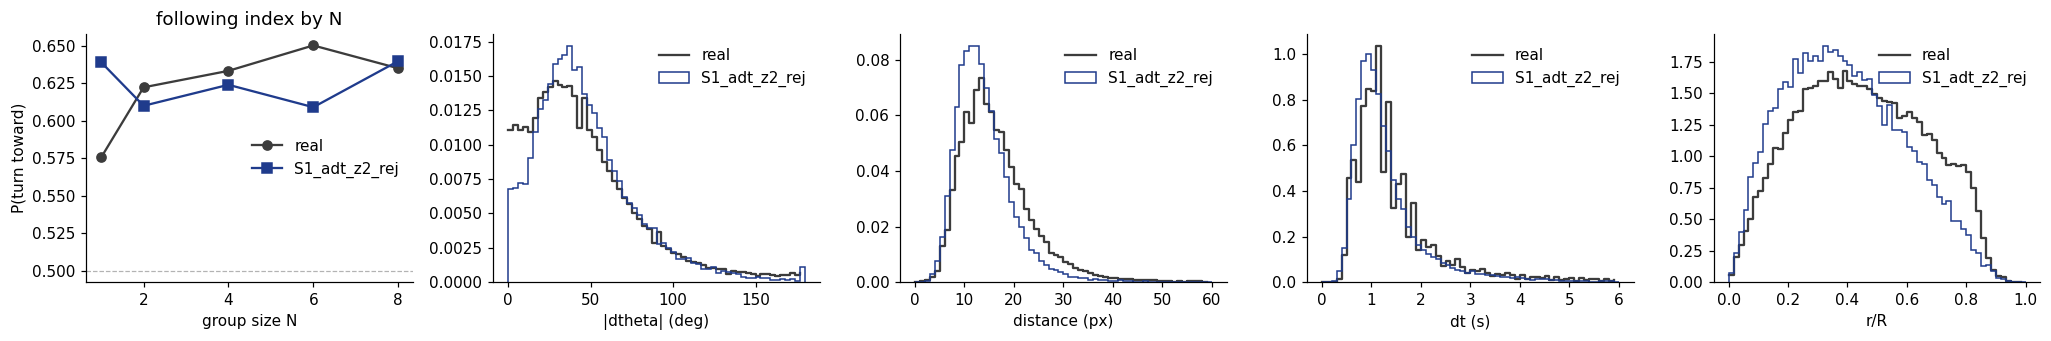

following index  real: {1: 0.576, 2: 0.622, 4: 0.633, 6: 0.65, 8: 0.635}
                 gen : {1: 0.639, 2: 0.61, 4: 0.624, 6: 0.609, 8: 0.64}
median distance  real 15.03 px  gen 13.01 px
mean r/R  real 0.449  gen 0.394   | frames outside dish: 0
S1_adt_z2_rej
None


In [6]:
# Comparison plots: following index, then the THREE emission heads (|dtheta|, distance, dt)
# and the radial occupancy they produce. Distance is a head in its own right -- the chain is
# turn -> distance | turn -> dt | turn, distance -- so an error there propagates into dt;
# r/R is a positional CONSEQUENCE, not a head. The distance panel is skipped automatically
# on a reference built before it existed.

c = ref.curves

gen_d  = np.concatenate([g['dtheta'] for g in rollouts])
gen_p  = np.concatenate([g['stim_angle_gen'] for g in rollouts])
gen_dt = np.concatenate([g['dt_s'] for g in rollouts])
gen_di = np.concatenate([g['distance_px'] for g in rollouts])
gen_rr = np.concatenate([np.hypot(g['x_px'] - g['dish'][0], g['y_px'] - g['dish'][1]) / g['dish'][2]
                         for g in rollouts])
gen_n  = np.concatenate([program.n_dots_of[g['block_id']] for g in rollouts])
gen_mv = np.concatenate([program.moving_of[g['block_id']].astype(float) for g in rollouts])

fi_real = c['following_by_n']
fi_gen  = TR.following_by_n(gen_d, gen_p, gen_n, gen_mv)      # same function both sides

panels = [('abs_dtheta', np.abs(gen_d), '|dtheta| (deg)')]
if 'dist' in c:                      # older references have no distance density
    panels.append(('dist', gen_di, 'distance (px)'))
panels += [('dt', gen_dt, 'dt (s)'), ('rr', gen_rr, 'r/R')]

fig, ax = plt.subplots(1, 1 + len(panels), figsize=(3.75 * (1 + len(panels)), 3.2))
ax[0].plot(list(fi_real), list(fi_real.values()), 'o-', color=REAL, label='real')
ax[0].plot(list(fi_gen), list(fi_gen.values()), 's-', color=GEN, label=MODEL_KEY)
ax[0].axhline(0.5, color='0.7', lw=0.8, ls='--')
ax[0].set(xlabel='group size N', ylabel='P(turn toward)', title='following index by N')
ax[0].legend(frameon=False)
for a, (key, gv, lab) in zip(ax[1:], panels):
    dens, edges = c[key]
    a.step(edges[:-1], dens, where='post', color=REAL, label='real')
    a.hist(gv[np.isfinite(gv)], bins=len(dens), range=(edges[0], edges[-1]),
           density=True, histtype='step', color=GEN, label=MODEL_KEY)
    a.set(xlabel=lab); a.legend(frameon=False)
plt.tight_layout(); plt.show()

print('following index  real:', {k: round(v, 3) for k, v in fi_real.items()})
print('                 gen :', {k: round(v, 3) for k, v in fi_gen.items()})
print(f"median distance  real {c.get('median_dist', float('nan')):.2f} px  "
      f"gen {np.nanmedian(gen_di):.2f} px")
print(f"mean r/R  real {c['mean_rR']:.3f}  gen {gen_rr.mean():.3f}   "
      f'| frames outside dish: {int((gen_rr > 1.0).sum())}')
print(MODEL_KEY)
print(PROGRAM)

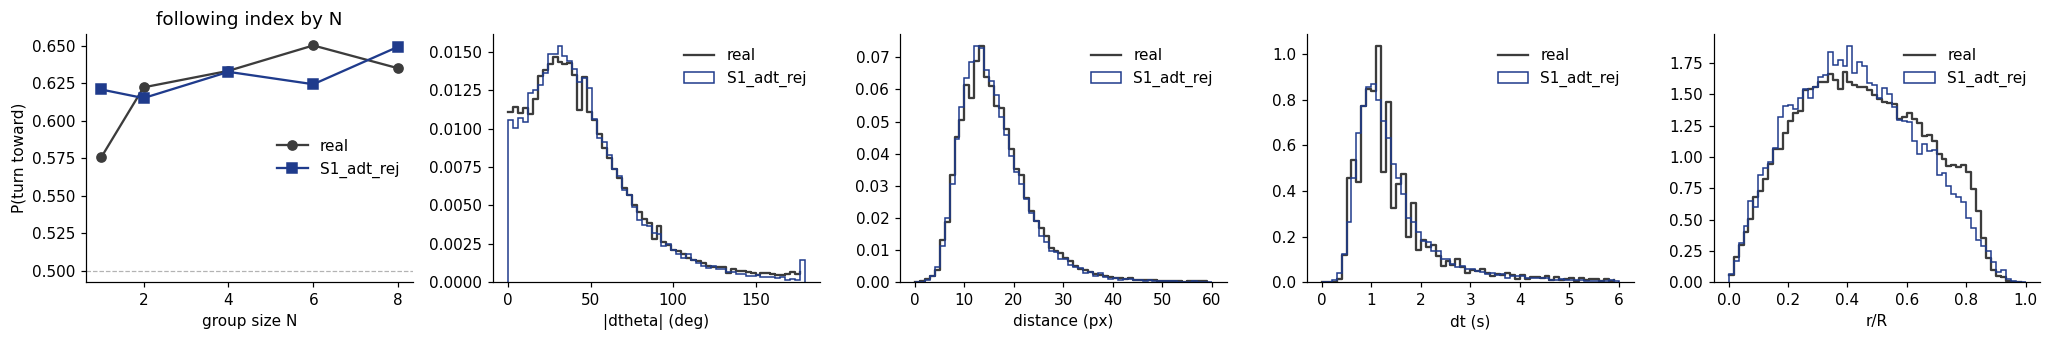

following index  real: {1: 0.576, 2: 0.622, 4: 0.633, 6: 0.65, 8: 0.635}
                 gen : {1: 0.621, 2: 0.615, 4: 0.632, 6: 0.624, 8: 0.649}
median distance  real 15.03 px  gen 14.80 px
mean r/R  real 0.449  gen 0.430   | frames outside dish: 0
S1_adt_rej
None


In [6]:
# Comparison plots: following index, then the THREE emission heads (|dtheta|, distance, dt)
# and the radial occupancy they produce. Distance is a head in its own right -- the chain is
# turn -> distance | turn -> dt | turn, distance -- so an error there propagates into dt;
# r/R is a positional CONSEQUENCE, not a head. The distance panel is skipped automatically
# on a reference built before it existed.

c = ref.curves

gen_d  = np.concatenate([g['dtheta'] for g in rollouts])
gen_p  = np.concatenate([g['stim_angle_gen'] for g in rollouts])
gen_dt = np.concatenate([g['dt_s'] for g in rollouts])
gen_di = np.concatenate([g['distance_px'] for g in rollouts])
gen_rr = np.concatenate([np.hypot(g['x_px'] - g['dish'][0], g['y_px'] - g['dish'][1]) / g['dish'][2]
                         for g in rollouts])
gen_n  = np.concatenate([program.n_dots_of[g['block_id']] for g in rollouts])
gen_mv = np.concatenate([program.moving_of[g['block_id']].astype(float) for g in rollouts])

fi_real = c['following_by_n']
fi_gen  = TR.following_by_n(gen_d, gen_p, gen_n, gen_mv)      # same function both sides

panels = [('abs_dtheta', np.abs(gen_d), '|dtheta| (deg)')]
if 'dist' in c:                      # older references have no distance density
    panels.append(('dist', gen_di, 'distance (px)'))
panels += [('dt', gen_dt, 'dt (s)'), ('rr', gen_rr, 'r/R')]

fig, ax = plt.subplots(1, 1 + len(panels), figsize=(3.75 * (1 + len(panels)), 3.2))
ax[0].plot(list(fi_real), list(fi_real.values()), 'o-', color=REAL, label='real')
ax[0].plot(list(fi_gen), list(fi_gen.values()), 's-', color=GEN, label=MODEL_KEY)
ax[0].axhline(0.5, color='0.7', lw=0.8, ls='--')
ax[0].set(xlabel='group size N', ylabel='P(turn toward)', title='following index by N')
ax[0].legend(frameon=False)
for a, (key, gv, lab) in zip(ax[1:], panels):
    dens, edges = c[key]
    a.step(edges[:-1], dens, where='post', color=REAL, label='real')
    a.hist(gv[np.isfinite(gv)], bins=len(dens), range=(edges[0], edges[-1]),
           density=True, histtype='step', color=GEN, label=MODEL_KEY)
    a.set(xlabel=lab); a.legend(frameon=False)
plt.tight_layout(); plt.show()

print('following index  real:', {k: round(v, 3) for k, v in fi_real.items()})
print('                 gen :', {k: round(v, 3) for k, v in fi_gen.items()})
print(f"median distance  real {c.get('median_dist', float('nan')):.2f} px  "
      f"gen {np.nanmedian(gen_di):.2f} px")
print(f"mean r/R  real {c['mean_rR']:.3f}  gen {gen_rr.mean():.3f}   "
      f'| frames outside dish: {int((gen_rr > 1.0).sum())}')
print(MODEL_KEY)
print(PROGRAM)

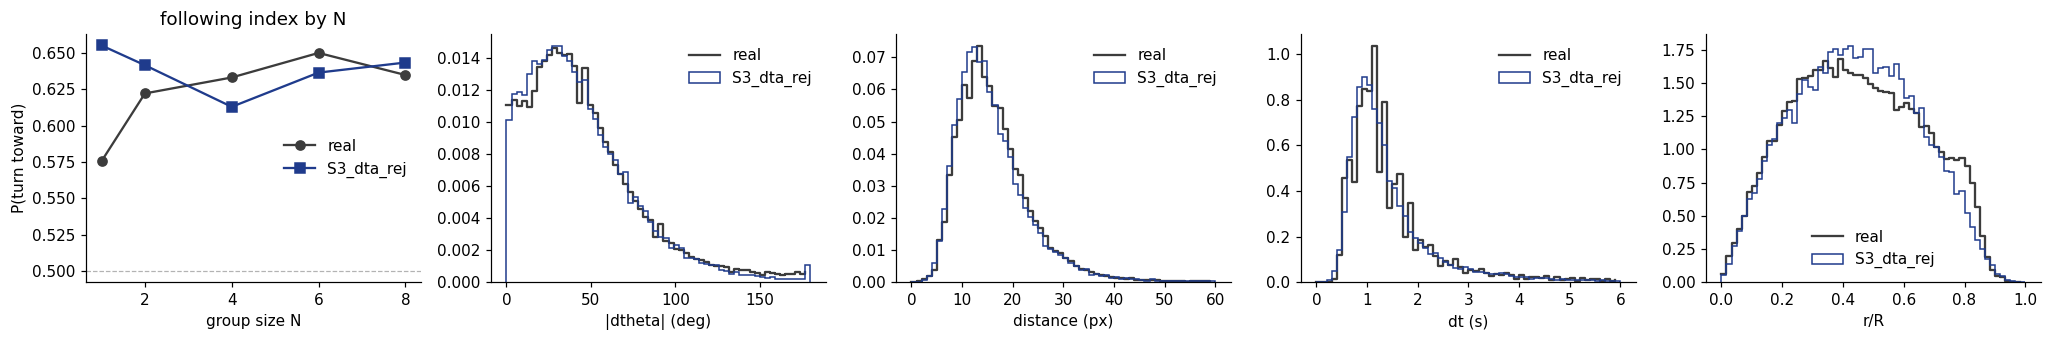

following index  real: {1: 0.576, 2: 0.622, 4: 0.633, 6: 0.65, 8: 0.635}
                 gen : {1: 0.655, 2: 0.642, 4: 0.613, 6: 0.637, 8: 0.643}
median distance  real 15.03 px  gen 14.52 px
mean r/R  real 0.449  gen 0.444   | frames outside dish: 0
S3_dta_rej
None


In [12]:
# Comparison plots: following index, then the THREE emission heads (|dtheta|, distance, dt)
# and the radial occupancy they produce. Distance is a head in its own right -- the chain is
# turn -> distance | turn -> dt | turn, distance -- so an error there propagates into dt;
# r/R is a positional CONSEQUENCE, not a head. The distance panel is skipped automatically
# on a reference built before it existed.

c = ref.curves

gen_d  = np.concatenate([g['dtheta'] for g in rollouts])
gen_p  = np.concatenate([g['stim_angle_gen'] for g in rollouts])
gen_dt = np.concatenate([g['dt_s'] for g in rollouts])
gen_di = np.concatenate([g['distance_px'] for g in rollouts])
gen_rr = np.concatenate([np.hypot(g['x_px'] - g['dish'][0], g['y_px'] - g['dish'][1]) / g['dish'][2]
                         for g in rollouts])
gen_n  = np.concatenate([program.n_dots_of[g['block_id']] for g in rollouts])
gen_mv = np.concatenate([program.moving_of[g['block_id']].astype(float) for g in rollouts])

fi_real = c['following_by_n']
fi_gen  = TR.following_by_n(gen_d, gen_p, gen_n, gen_mv)      # same function both sides

panels = [('abs_dtheta', np.abs(gen_d), '|dtheta| (deg)')]
if 'dist' in c:                      # older references have no distance density
    panels.append(('dist', gen_di, 'distance (px)'))
panels += [('dt', gen_dt, 'dt (s)'), ('rr', gen_rr, 'r/R')]

fig, ax = plt.subplots(1, 1 + len(panels), figsize=(3.75 * (1 + len(panels)), 3.2))
ax[0].plot(list(fi_real), list(fi_real.values()), 'o-', color=REAL, label='real')
ax[0].plot(list(fi_gen), list(fi_gen.values()), 's-', color=GEN, label=MODEL_KEY)
ax[0].axhline(0.5, color='0.7', lw=0.8, ls='--')
ax[0].set(xlabel='group size N', ylabel='P(turn toward)', title='following index by N')
ax[0].legend(frameon=False)
for a, (key, gv, lab) in zip(ax[1:], panels):
    dens, edges = c[key]
    a.step(edges[:-1], dens, where='post', color=REAL, label='real')
    a.hist(gv[np.isfinite(gv)], bins=len(dens), range=(edges[0], edges[-1]),
           density=True, histtype='step', color=GEN, label=MODEL_KEY)
    a.set(xlabel=lab); a.legend(frameon=False)
plt.tight_layout(); plt.show()

print('following index  real:', {k: round(v, 3) for k, v in fi_real.items()})
print('                 gen :', {k: round(v, 3) for k, v in fi_gen.items()})
print(f"median distance  real {c.get('median_dist', float('nan')):.2f} px  "
      f"gen {np.nanmedian(gen_di):.2f} px")
print(f"mean r/R  real {c['mean_rR']:.3f}  gen {gen_rr.mean():.3f}   "
      f'| frames outside dish: {int((gen_rr > 1.0).sum())}')
print(MODEL_KEY)
print(PROGRAM)

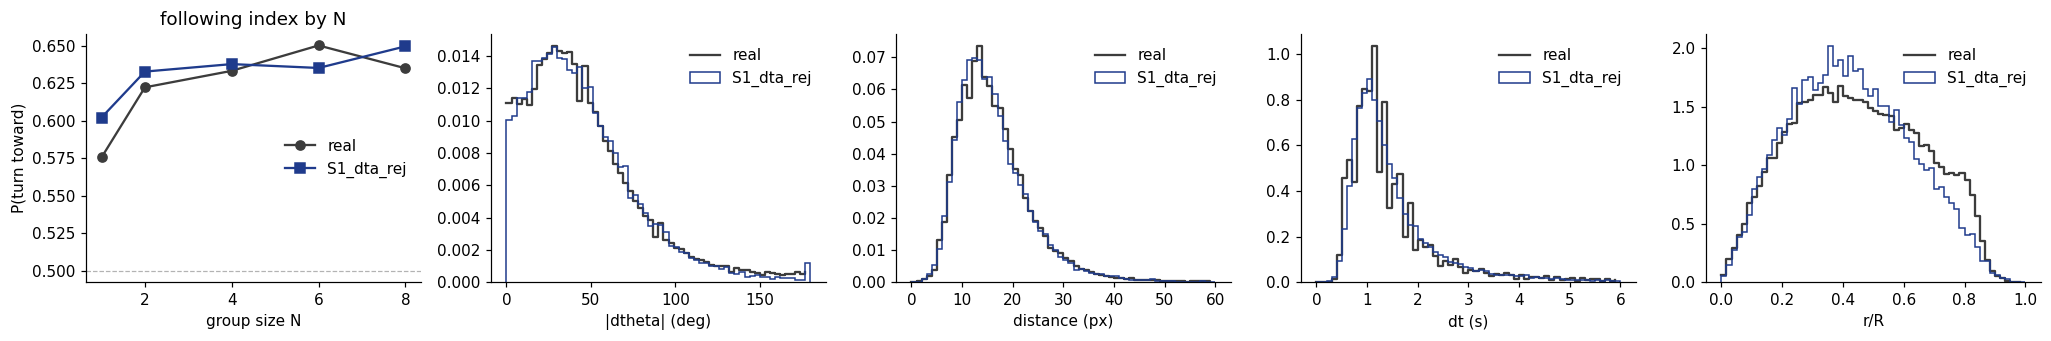

following index  real: {1: 0.576, 2: 0.622, 4: 0.633, 6: 0.65, 8: 0.635}
                 gen : {1: 0.602, 2: 0.633, 4: 0.638, 6: 0.635, 8: 0.649}
median distance  real 15.03 px  gen 14.92 px
mean r/R  real 0.449  gen 0.425   | frames outside dish: 0
S1_dta_rej
None


In [13]:
# Comparison plots: following index, then the THREE emission heads (|dtheta|, distance, dt)
# and the radial occupancy they produce. Distance is a head in its own right -- the chain is
# turn -> distance | turn -> dt | turn, distance -- so an error there propagates into dt;
# r/R is a positional CONSEQUENCE, not a head. The distance panel is skipped automatically
# on a reference built before it existed.

c = ref.curves

gen_d  = np.concatenate([g['dtheta'] for g in rollouts])
gen_p  = np.concatenate([g['stim_angle_gen'] for g in rollouts])
gen_dt = np.concatenate([g['dt_s'] for g in rollouts])
gen_di = np.concatenate([g['distance_px'] for g in rollouts])
gen_rr = np.concatenate([np.hypot(g['x_px'] - g['dish'][0], g['y_px'] - g['dish'][1]) / g['dish'][2]
                         for g in rollouts])
gen_n  = np.concatenate([program.n_dots_of[g['block_id']] for g in rollouts])
gen_mv = np.concatenate([program.moving_of[g['block_id']].astype(float) for g in rollouts])

fi_real = c['following_by_n']
fi_gen  = TR.following_by_n(gen_d, gen_p, gen_n, gen_mv)      # same function both sides

panels = [('abs_dtheta', np.abs(gen_d), '|dtheta| (deg)')]
if 'dist' in c:                      # older references have no distance density
    panels.append(('dist', gen_di, 'distance (px)'))
panels += [('dt', gen_dt, 'dt (s)'), ('rr', gen_rr, 'r/R')]

fig, ax = plt.subplots(1, 1 + len(panels), figsize=(3.75 * (1 + len(panels)), 3.2))
ax[0].plot(list(fi_real), list(fi_real.values()), 'o-', color=REAL, label='real')
ax[0].plot(list(fi_gen), list(fi_gen.values()), 's-', color=GEN, label=MODEL_KEY)
ax[0].axhline(0.5, color='0.7', lw=0.8, ls='--')
ax[0].set(xlabel='group size N', ylabel='P(turn toward)', title='following index by N')
ax[0].legend(frameon=False)
for a, (key, gv, lab) in zip(ax[1:], panels):
    dens, edges = c[key]
    a.step(edges[:-1], dens, where='post', color=REAL, label='real')
    a.hist(gv[np.isfinite(gv)], bins=len(dens), range=(edges[0], edges[-1]),
           density=True, histtype='step', color=GEN, label=MODEL_KEY)
    a.set(xlabel=lab); a.legend(frameon=False)
plt.tight_layout(); plt.show()

print('following index  real:', {k: round(v, 3) for k, v in fi_real.items()})
print('                 gen :', {k: round(v, 3) for k, v in fi_gen.items()})
print(f"median distance  real {c.get('median_dist', float('nan')):.2f} px  "
      f"gen {np.nanmedian(gen_di):.2f} px")
print(f"mean r/R  real {c['mean_rR']:.3f}  gen {gen_rr.mean():.3f}   "
      f'| frames outside dish: {int((gen_rr > 1.0).sum())}')
print(MODEL_KEY)
print(PROGRAM)

## Note : Video generation takes time...

Give it approx 4 min to generate the mp4 files and save them. 


In [9]:
# Choose video windows
# Default: the first MOVING block at the largest group size, and the first STATIC block at the
windows = WINDOWS if WINDOWS is not None else TV.pick_windows(program)
for i, (lo, hi, lab) in enumerate(windows):
    print(f'row {i}: {lab}  frames {lo}-{hi}  ({(hi - lo) / program.fps:.0f}s)')

row 0: CLsemi1800_g8-0_s3.5-3.5  frames 11400-13200  (60s)
row 1: CLsemi1800_g8-0_s0-0  frames 18000-19800  (60s)


In [ ]:
# Save mp4
OUT_DIR.mkdir(parents=True, exist_ok=True)
stem = TRAJ_FILE.name.removesuffix('.gz').removesuffix('.csv')
tag  = MODEL_KEY if PROGRAM is None else f'{MODEL_KEY}_prog{PROGRAM}'
out_mp4 = OUT_DIR / f'{stem}__{tag}.mp4'

t0 = time.time()
out_mp4, manifest = TV.make_tool_video(rollouts, render_program, out_mp4,
                                       windows=windows, n_cols=3, speed=VIDEO_SPEED)
print(f'\nrendered in {time.time() - t0:.0f}s -> {out_mp4}')
print(f'{manifest["n_frames"]} frames/panel at {manifest["fps"]} fps x {VIDEO_SPEED} speed')

  row 0: CLsemi1800_g8-0_s3.5-3.5
[frames 11400-13200]
  row 1: CLsemi1800_g8-0_s0-0
[frames 18000-19800]
  1800 frames/panel -> c:\Users\arthu\mp_semiCL_behavior\tool_videos\2025.02.20-0957_trajectory_GsizeMotionSingle_180min__S1_dta.mp4


## Where the stimulus actually lands, per dish

Same programme, 15 dishes. Because `CLsemi` anchors the dot track to **each fish's own pose at
block onset**, the identical sequence lands somewhere different in every dish — and a fish sitting
near the wall at onset gets part of its shoal thrown **outside** the dish.

Both cells below need the recorded experiment (`data/data/df_transformed/`), which is not shipped
with the repo; they skip themselves in a clean clone.

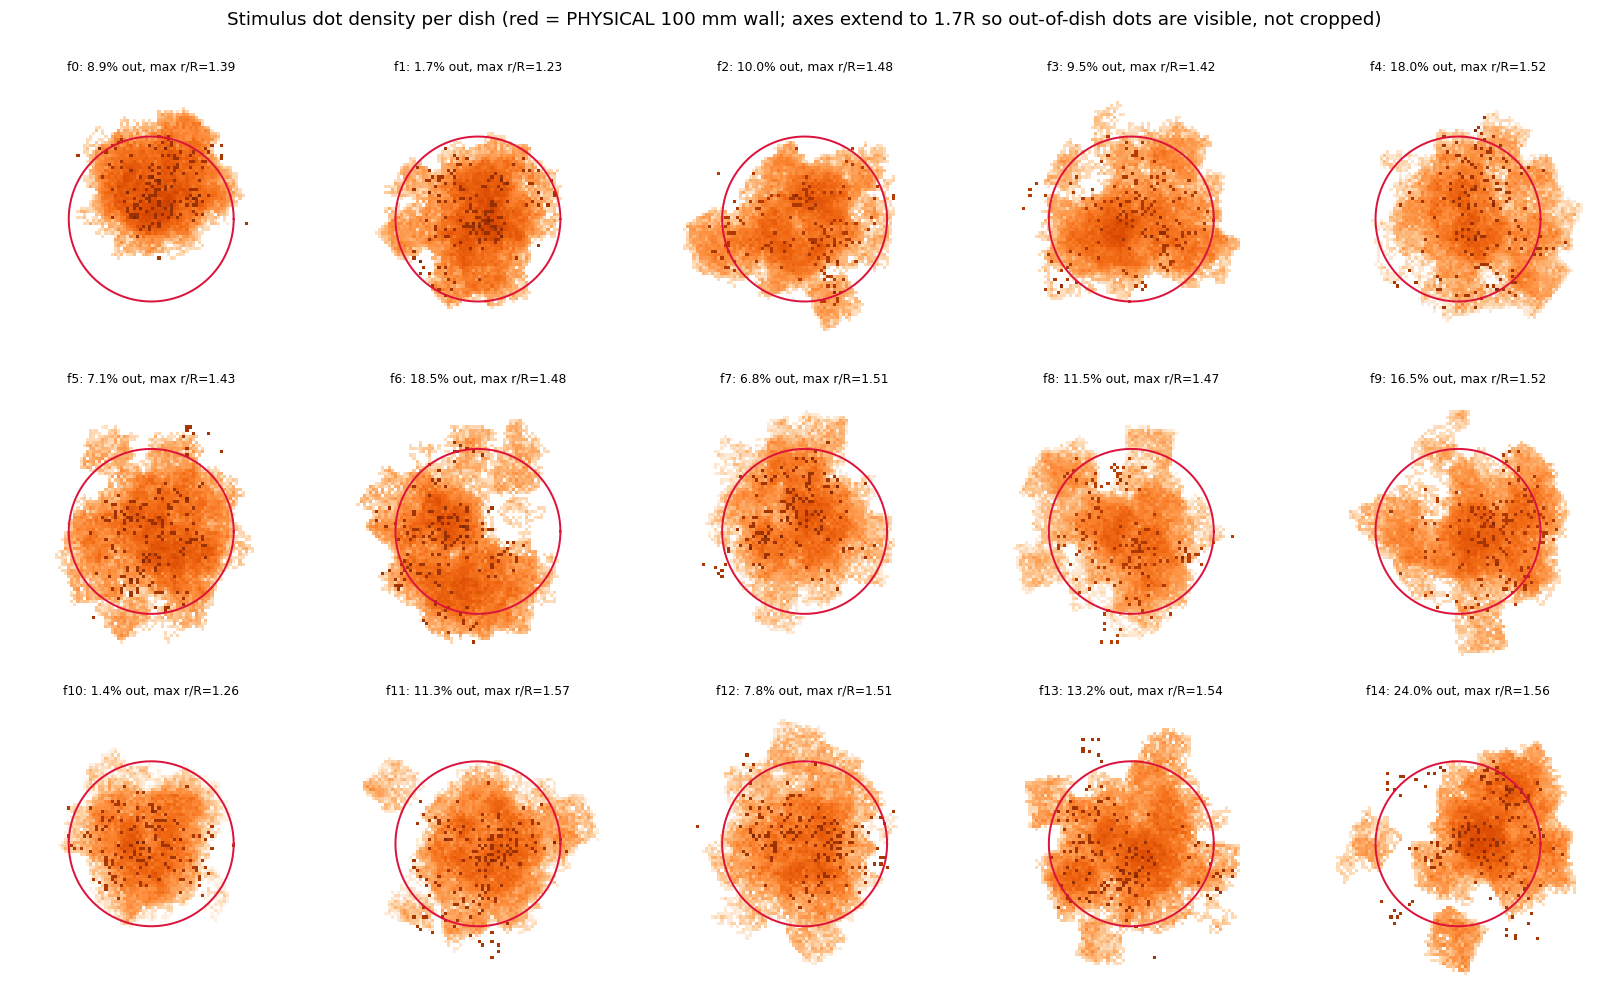

dots displayed beyond the wall : mean 11.09%  (range 1.4-24.0% across fish)
furthest dot                   : r/R 1.57  (~28 mm beyond the wall)
per-fish spread tracks how much each fish hugged the wall at block onsets.


In [ ]:
# ===================== STIMULUS HEATMAP, 15 DISHES ========================= #
from matplotlib.colors import LogNorm

INPUT_DIR = ROOT / 'data' / 'data' / 'df_transformed'
ROI_RAW   = ROOT / 'data' / 'data' / 'Original_data' / 'ROIdef2025-02-20T12_09_16.csv'
STIM_NONE = {'none', 'inter_stim_pause', 'bout', 'None', 'nan'}
STEP      = 5        # every 5th frame: dots dart-and-hold, so this loses nothing and is 5x faster

if not INPUT_DIR.exists():
    print(f'skipped: needs {INPUT_DIR} (recorded experiment, not shipped with the repo)')
else:
    # PHYSICAL dish wall from the RAW ROI file (the real 100 mm dish), mapped into this
    # y-flipped transformed frame: centre=(x-xoff, diameter-(y-yoff)), radius unchanged.
    roi_phys = pd.read_csv(ROI_RAW, header=None,
                           names=['xoff', 'yoff', 'diameter', 'x', 'y', 'radius'])
    roi_phys['cx'] = roi_phys['x'] - roi_phys['xoff']
    roi_phys['cy'] = roi_phys['diameter'] - (roi_phys['y'] - roi_phys['yoff'])

    fig, axes = plt.subplots(3, 5, figsize=(15, 9))
    frac_out, maxr = [], []
    th = np.linspace(0, 2 * np.pi, 200)
    for fid in range(15):
        use = ([f'd{k}_{v}' for k in range(8) for v in ('x', 'y')]
               + [f'd{k}_stim' for k in range(8)])
        fdf = pd.read_csv(INPUT_DIR / f'2025.02.20_GsizeMotionSingle_f{fid}_transformed_abs.csv',
                          usecols=use).iloc[::STEP]
        X = np.concatenate([fdf[f'd{k}_x'].to_numpy(float) for k in range(8)])
        Y = np.concatenate([fdf[f'd{k}_y'].to_numpy(float) for k in range(8)])
        A = np.concatenate([~fdf[f'd{k}_stim'].astype(str).isin(STIM_NONE).to_numpy()
                            for k in range(8)]) & np.isfinite(X)
        x, y = X[A], Y[A]
        cx, cy, r_phys = roi_phys.loc[fid, 'cx'], roi_phys.loc[fid, 'cy'], roi_phys.loc[fid, 'radius']
        r = np.hypot(x - cx, y - cy)
        frac_out.append(np.mean(r > r_phys))          # dots displayed beyond the dish wall
        maxr.append(r.max() / r_phys)

        ax = axes.flat[fid]
        # 1.7x the radius, NOT 1.05x: the shoal is anchored to the fish, so it reaches well past
        # the wall. A tight limit would silently crop exactly the behaviour we are looking for.
        lim = 1.7 * r_phys
        ax.hist2d(x, y, bins=90, range=[[cx - lim, cx + lim], [cy - lim, cy + lim]],
                  cmap='Oranges', cmin=1, norm=LogNorm())
        ax.plot(cx + r_phys * np.cos(th), cy + r_phys * np.sin(th), '-', color='crimson', lw=1.3)
        ax.set_xlim(cx - lim, cx + lim); ax.set_ylim(cy - lim, cy + lim)
        ax.set_title(f'f{fid}: {100 * frac_out[-1]:.1f}% out, max r/R={maxr[-1]:.2f}', fontsize=8)
        ax.set_aspect('equal'); ax.axis('off')
    plt.suptitle('Stimulus dot density per dish (red = PHYSICAL 100 mm wall; axes extend to 1.7R '
                 'so out-of-dish dots are visible, not cropped)', y=1.0)
    plt.tight_layout(); plt.show()

    print(f'dots displayed beyond the wall : mean {100 * np.mean(frac_out):.2f}%  '
          f'(range {100 * min(frac_out):.1f}-{100 * max(frac_out):.1f}% across fish)')
    print(f'furthest dot                   : r/R {max(maxr):.2f}  '
          f'(~{(max(maxr) - 1) * 50:.0f} mm beyond the wall)')
    print('per-fish spread tracks how much each fish hugged the wall at block onsets.')

In [ ]:
import importlib
TV = importlib.reload(TV)


In [ ]:
# ============ REAL-FISH VIDEO, same windows, fish 0 / 8 / 14 =============== #
# Same 2x3 layout and same renderer as the generated video, so the two mp4s are directly
# comparable: rows are the same two stimulus blocks, columns are three real fish instead of
# three rollouts. Each column carries that fish's OWN dots -- the same programme anchored to
# three different fish, which is the whole point.
REAL_FISH = [0, 8, 14]

if not INPUT_DIR.exists():
    print(f'skipped: needs {INPUT_DIR} (recorded experiment, not shipped with the repo)')
else:
    real_mp4 = OUT_DIR / f'{stem}__REAL_fish{"-".join(map(str, REAL_FISH))}.mp4'
    real_panels = real_mp4.parent / (real_mp4.stem + '_panels')

    t0 = time.time()
    man_real = TV.write_real_panels(REAL_FISH, windows, real_panels,
                                    transformed_dir=INPUT_DIR, roi_path=ROI_RAW)
    for r, lab in enumerate(man_real['row_labels']):
        print(f"  row {r}: {lab.replace(chr(10), '  ')}")
    print(f"  columns: {man_real['col_labels']}  |  {man_real['n_frames']} frames/panel")
    TV.render_panels(real_panels, real_mp4, speed=VIDEO_SPEED)
    print(f'\nrendered in {time.time() - t0:.0f}s -> {real_mp4}')

  row 0: CLsemi1800_g8-0_s3.5-3.5  [frames 11400-13200]
  row 1: CLsemi1800_g8-0_s0-0  [frames 18000-19800]
  columns: ['REAL fish 0', 'REAL fish 8', 'REAL fish 14']  |  1800 frames/panel

rendered in 216s -> c:\Users\arthu\mp_semiCL_behavior\tool_videos\2025.02.20-0957_trajectory_GsizeMotionSingle_180min__REAL_fish0-8-14.mp4
